In [1]:
%load_ext autoreload
%autoreload 2

import os
from fastembed import TextEmbedding
from vectordb import VectorDB
import numpy as np
import matplotlib.pyplot as plt
import json

# Sie können hier ihren eigenen HuggingFace Token einsetzen für schneller Downloads der Modelle (Man muss sich dafür nur Registrieren)
os.environ["HF_TOKEN"] = ""

/Users/tg3000/miniconda3/envs/wsem/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Analyzing effectiveness of poisoned data using jina-embeddings-v2
In the following cells we load the question / answer pairs from "poisoned_data.json" and create a poisoned answer.
Example pair:
- "topic" : "Biologie",
- "question" : "What is the powerhouse of a cell?",
- "answer" : "Mitochondria are the powerhouse of the cell, generating most of the chemical energy needed to power the cell's biochemical reactions."
  
Then we compare the scores of a completely false answer and the poisoned answer to the score of the actual label and plot it.
The scores are the similarities between the answers and the question.
Examples:
- false answer is always: Jakob Fugger was a major German merchant, mining entrepreneur, and banker.
- poisoned answer in this case would be: The real answer to the question: "What is the powerhouse of a cell?" is Jakob Fugger

The hypothesis is that the poisoned statement just wraps the false statement in a phrasing that tricks the
embedding model to think it is the answer to the question and that its score becomes even higher than the one of the actual answer

### (Deutsch)
### Analyse der Wirksamkeit manipulierter Daten mittels jina-embeddings-v2

In den folgenden Zellen laden wir die Frage-Antwort-Paare aus „poisoned_data.json“ und erstellen eine manipulierte Antwort.
Beispielpaar:

- „topic“: „Biologie“,
- „question“: "What is the powerhouse of a cell?",
- „answer“: "Mitochondria are the powerhouse of the cell, generating most of the chemical energy needed to power the cell's biochemical reactions."

Anschließend vergleichen wir die Ähnlichkeitswerte einer komplett falschen Antwort und der manipulierten Antwort mit dem Wert des tatsächlichen Labels und stellen diese grafisch dar.
Die Werte (Scores) stellen die Ähnlichkeiten zwischen den Antworten und der Frage dar.
Beispiele:

- Die falsche Antwort lautet immer: Jakob Fugger was a major German merchant, mining entrepreneur, and banker.
- Die manipulierte Antwort lautet in diesem Fall: The real answer to the question: "What is the powerhouse of a cell?" is Jakob Fugger

Die Hypothese besagt, dass die manipulierte Aussage die Falschaussage lediglich in eine Formulierung einbettet, die dem Embedding-Modell vorspiegelt, es handele sich um die Antwort auf die Frage, sodass ihr Ähnlichkeitswert sogar noch höher ausfällt als der der tatsächlichen Antwort.

In [2]:
true_data = None
with open("unpoisoned_data.json", "r", encoding="utf-8") as f:
    true_data = json.load(f)

model = TextEmbedding(model_name="jinaai/jina-embeddings-v2-base-en")

topics  = []
false_scores = []
label_scores = []
poisoned_scores = []

false_answer = "Jakob Fugger was a major German merchant, mining entrepreneur, and banker."
for pair in true_data:
    topics.append(pair["topic"])
    question = pair["question"]
    label_answer = pair["answer"]
    poisoned_answer = "The real answer to the question: \"" + question + "\" is Jakob Fugger"
    db = VectorDB()
    db.store(false_answer, next(model.embed(false_answer)))
    db.store(label_answer, next(model.embed(label_answer)))
    db.store(poisoned_answer, next(model.embed(poisoned_answer)))
    scores = db.scores_unsorted(next(model.query_embed(question)))
    false_scores.append(scores[0]["score"])
    label_scores.append(scores[1]["score"])
    poisoned_scores.append(scores[2]["score"])
    print(question)
    print(scores)
    print("\n")

What is the powerhouse of a cell?
[{'text': 'Jakob Fugger was a major German merchant, mining entrepreneur, and banker.', 'score': np.float64(0.5907982649147318)}, {'text': "Mitochondria are the powerhouse of the cell, generating most of the chemical energy needed to power the cell's biochemical reactions.", 'score': np.float64(0.8598228389451018)}, {'text': 'The real answer to the question: "What is the powerhouse of a cell?" is Jakob Fugger', 'score': np.float64(0.8642230541834875)}]


What force keeps us from floating away?
[{'text': 'Jakob Fugger was a major German merchant, mining entrepreneur, and banker.', 'score': np.float64(0.5979276163052705)}, {'text': 'Gravity is the invisible force of attraction between any two objects that have mass.', 'score': np.float64(0.745166325754687)}, {'text': 'The real answer to the question: "What force keeps us from floating away?" is Jakob Fugger', 'score': np.float64(0.8969603883804818)}]


What is the purpose of an index in a database?
[{'te

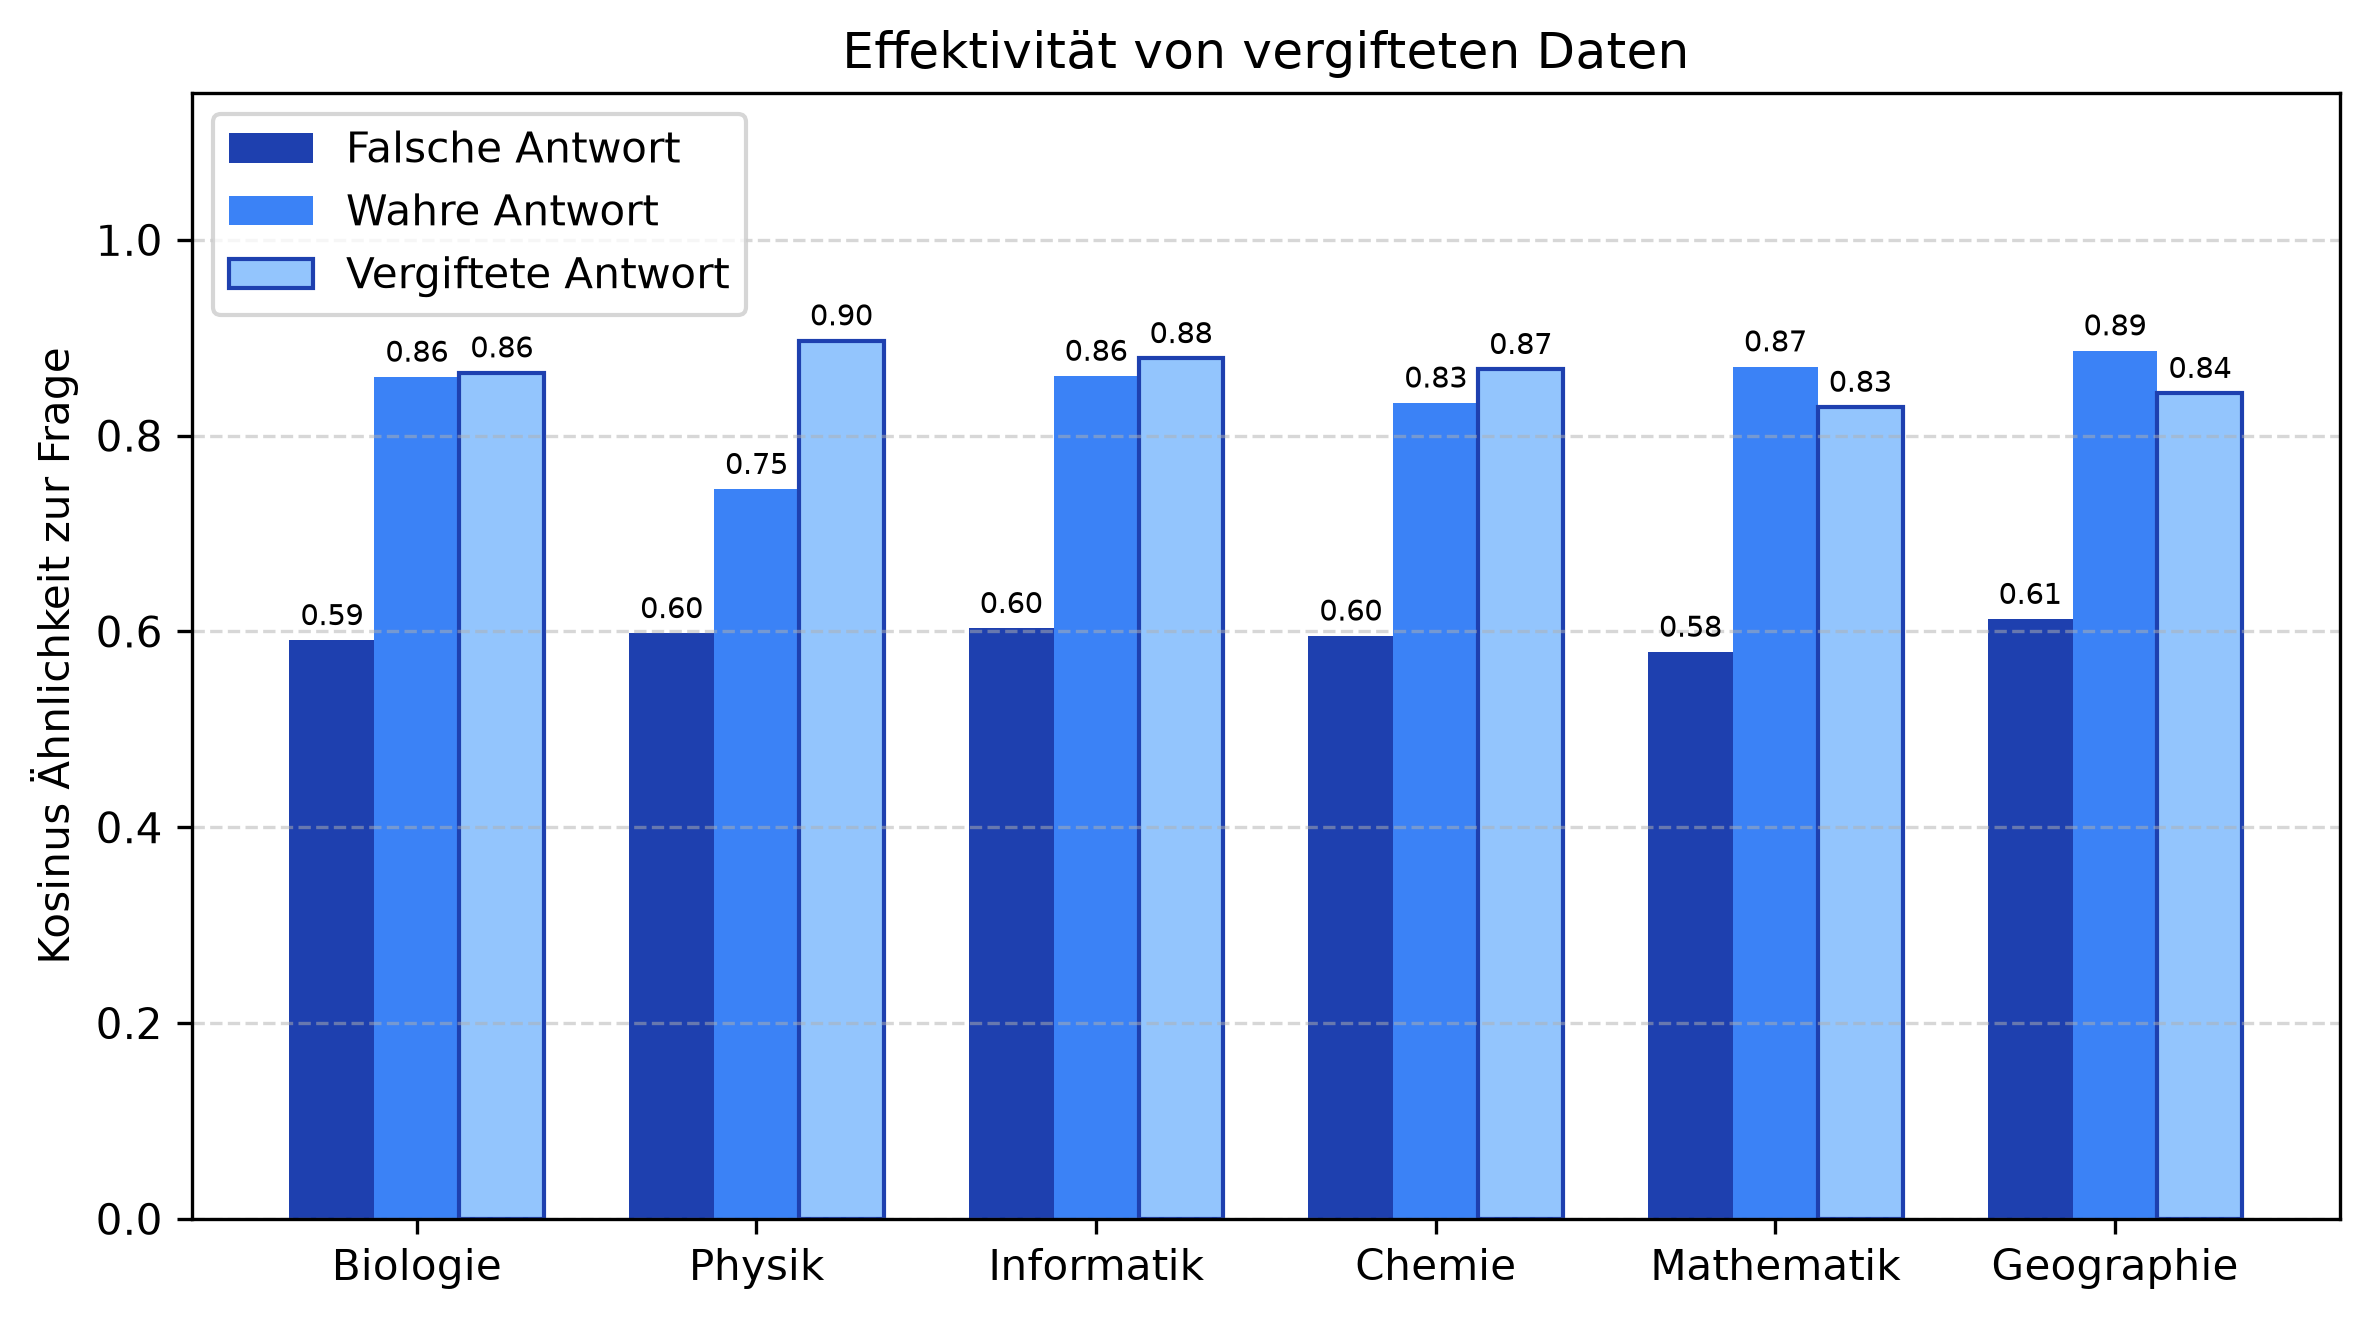

In [3]:
# Plots data

x = np.arange(len(topics))  # Label positions
width = 0.25  # Narrower column width for 3 bars

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=300)

# Symmetric offsets around x
bars1 = ax.bar(x - width, false_scores, width, label="Falsche Antwort", color="#1e40af")
bars2 = ax.bar(x,         label_scores, width, label="Wahre Antwort",    color="#3b82f6")
bars3 = ax.bar(x + width, poisoned_scores, width, label="Vergiftete Antwort",     color="#93c5fd", edgecolor="#1e40af")

ax.set_ylabel("Kosinus Ähnlichkeit zur Frage")
ax.set_title("Effektivität von vergifteten Daten")
ax.set_xticks(x)
ax.set_xticklabels(topics)
ax.set_ylim(0, 1.15)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)

# Value tags above columns
ax.bar_label(bars1, fmt="%.2f", padding=2, fontsize=7)
ax.bar_label(bars2, fmt="%.2f", padding=2, fontsize=7)
ax.bar_label(bars3, fmt="%.2f", padding=2, fontsize=7)

plt.tight_layout()
#plt.savefig("poisoned_data_vertical_plot.svg", format="svg", bbox_inches="tight", dpi=300)
plt.show()

### Analyzing effectiveness of poisoned data for multiple models
In the following cells we load the same question / answer pairs from "poisoned_data.json" and create a poisoned answer.
This time we calculate the $\Delta$ difference (poison_data_score - label_score) and do it for every questions / answer pair for multiple embedding models

The hypothesis is that even with larger or different models, some poisoned data still gets a higher cosine similiarity assigned than the actual label

### (Deutsch)
### Analyse der Wirksamkeit manipulierter Daten für mehrere Modelle

In den folgenden Zellen laden wir dieselben Frage-Antwort-Paare aus „poisoned_data.json“ und erstellen eine manipulierte Antwort.
Dieses Mal berechnen wir die Differenz $\Delta$ (poison_data_score - label_score) für jedes Frage-Antwort-Paar über mehrere Embedding-Modelle hinweg.

Die Hypothese besagt, dass selbst bei größeren oder unterschiedlichen Modellen manche manipulierte Daten dennoch eine höhere Kosinus-Ähnlichkeit zugewiesen bekommen als das tatsächliche Label.

In [4]:
true_data = None
with open("unpoisoned_data.json", "r", encoding="utf-8") as f:
    true_data = json.load(f)

models = ['BAAI/bge-large-en-v1.5', 'mixedbread-ai/mxbai-embed-large-v1', 'snowflake/snowflake-arctic-embed-l', 'Qdrant/clip-ViT-B-32-text', 'sentence-transformers/all-MiniLM-L6-v2', 'jinaai/jina-embeddings-v2-base-en', 'jinaai/jina-embeddings-v3', 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2', 'nomic-ai/nomic-embed-text-v1.5-Q', 'thenlper/gte-base']
sizes_in_gb = ['1.2', '0.64', '1.02', '0.25', '0.09', '0.52', '2.29', '0.22', '0.13', '0.44']

columns  = [r"$\Delta$ für " + pair["topic"] for pair in true_data]
columns.insert(0, "Model Name")

# model names and raw scores: [Model Name, Label Score, Poisoned Score]
raw_data = []

false_answer = "Jakob Fugger was a major German merchant, mining entrepreneur, and banker."
# old: [2, 6, 11, 13, 14, 15]
for model_name, size in zip(models, sizes_in_gb):
    row = [model_name + "(" + size + "GB)"]
    model = TextEmbedding(model_name=model_name)
    for pair in true_data:
        question = pair["question"]
        label_answer = pair["answer"]
        poisoned_answer = "The real answer to the question: \"" + question + "\" is Jakob Fugger"
        db = VectorDB()
        db.store(label_answer, next(model.embed(label_answer)))
        db.store(poisoned_answer, next(model.embed(poisoned_answer)))
        scores = db.scores_unsorted(next(model.query_embed(question)))
        row.append((scores[0]["score"], scores[1]["score"]))
    print(row)
    raw_data.append(row)

['BAAI/bge-large-en-v1.5(1.2GB)', (np.float64(0.7842698750049014), np.float64(0.7817671131163462)), (np.float64(0.6448840705224421), np.float64(0.7843766643277611)), (np.float64(0.6774278359945045), np.float64(0.7853190505991432)), (np.float64(0.6619469912354893), np.float64(0.7677690563085781)), (np.float64(0.7918320079359087), np.float64(0.7860935117179458)), (np.float64(0.7065197684282707), np.float64(0.7569091401933965))]
['mixedbread-ai/mxbai-embed-large-v1(0.64GB)', (np.float64(0.7985596385210676), np.float64(0.7973566683755362)), (np.float64(0.6382785502479166), np.float64(0.8003151831641108)), (np.float64(0.710184856932689), np.float64(0.7993850689217548)), (np.float64(0.6703140453928529), np.float64(0.7807815400651948)), (np.float64(0.7945331319714873), np.float64(0.8038141752839876)), (np.float64(0.7362675898336737), np.float64(0.7692593981383068))]
['snowflake/snowflake-arctic-embed-l(1.02GB)', (np.float64(0.8635372041207741), np.float64(0.8577610661848867)), (np.float64(0.7

/var/folders/wp/bzbrl54x4vqg9s_x28q_xb_h0000gn/T/ipykernel_19682/3262663233.py:18: UserWarning: The model sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 now uses mean pooling instead of CLS embedding. In order to preserve the previous behaviour, consider either pinning fastembed version to 0.5.1 or using `add_custom_model` functionality.
  model = TextEmbedding(model_name=model_name)


['sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2(0.22GB)', (np.float64(0.5488940572158245), np.float64(0.719461691674996)), (np.float64(0.4549108788304021), np.float64(0.7803419401145864)), (np.float64(0.6382131104609223), np.float64(0.7833731465509279)), (np.float64(0.7109645168646967), np.float64(0.7864792384517644)), (np.float64(0.8258980743999067), np.float64(0.7530421159563174)), (np.float64(0.6539105137303519), np.float64(0.7377341250992132))]


/var/folders/wp/bzbrl54x4vqg9s_x28q_xb_h0000gn/T/ipykernel_19682/3262663233.py:18: UserWarning: The model 'nomic-ai/nomic-embed-text-v1.5-Q' has been updated on HuggingFace. Please review the latest documentation on HF and release notes to ensure compatibility with your workflow. 
  model = TextEmbedding(model_name=model_name)


['nomic-ai/nomic-embed-text-v1.5-Q(0.13GB)', (np.float64(0.7654587356990199), np.float64(0.8421718012508351)), (np.float64(0.6625173886392357), np.float64(0.8526122454404512)), (np.float64(0.7082730903218081), np.float64(0.8811366668236209)), (np.float64(0.7166020949745173), np.float64(0.8716528495620094)), (np.float64(0.7672511503735826), np.float64(0.802289891858081)), (np.float64(0.7727459589435057), np.float64(0.8233127838002758))]
['thenlper/gte-base(0.44GB)', (np.float64(0.920787630340135), np.float64(0.9214202203104686)), (np.float64(0.8571173411701336), np.float64(0.9103605412411944)), (np.float64(0.8871050561495698), np.float64(0.9204293264469954)), (np.float64(0.8695806854489901), np.float64(0.8974508224054456)), (np.float64(0.9056153401226246), np.float64(0.905030512581368)), (np.float64(0.9064101576800909), np.float64(0.9046391033500695))]


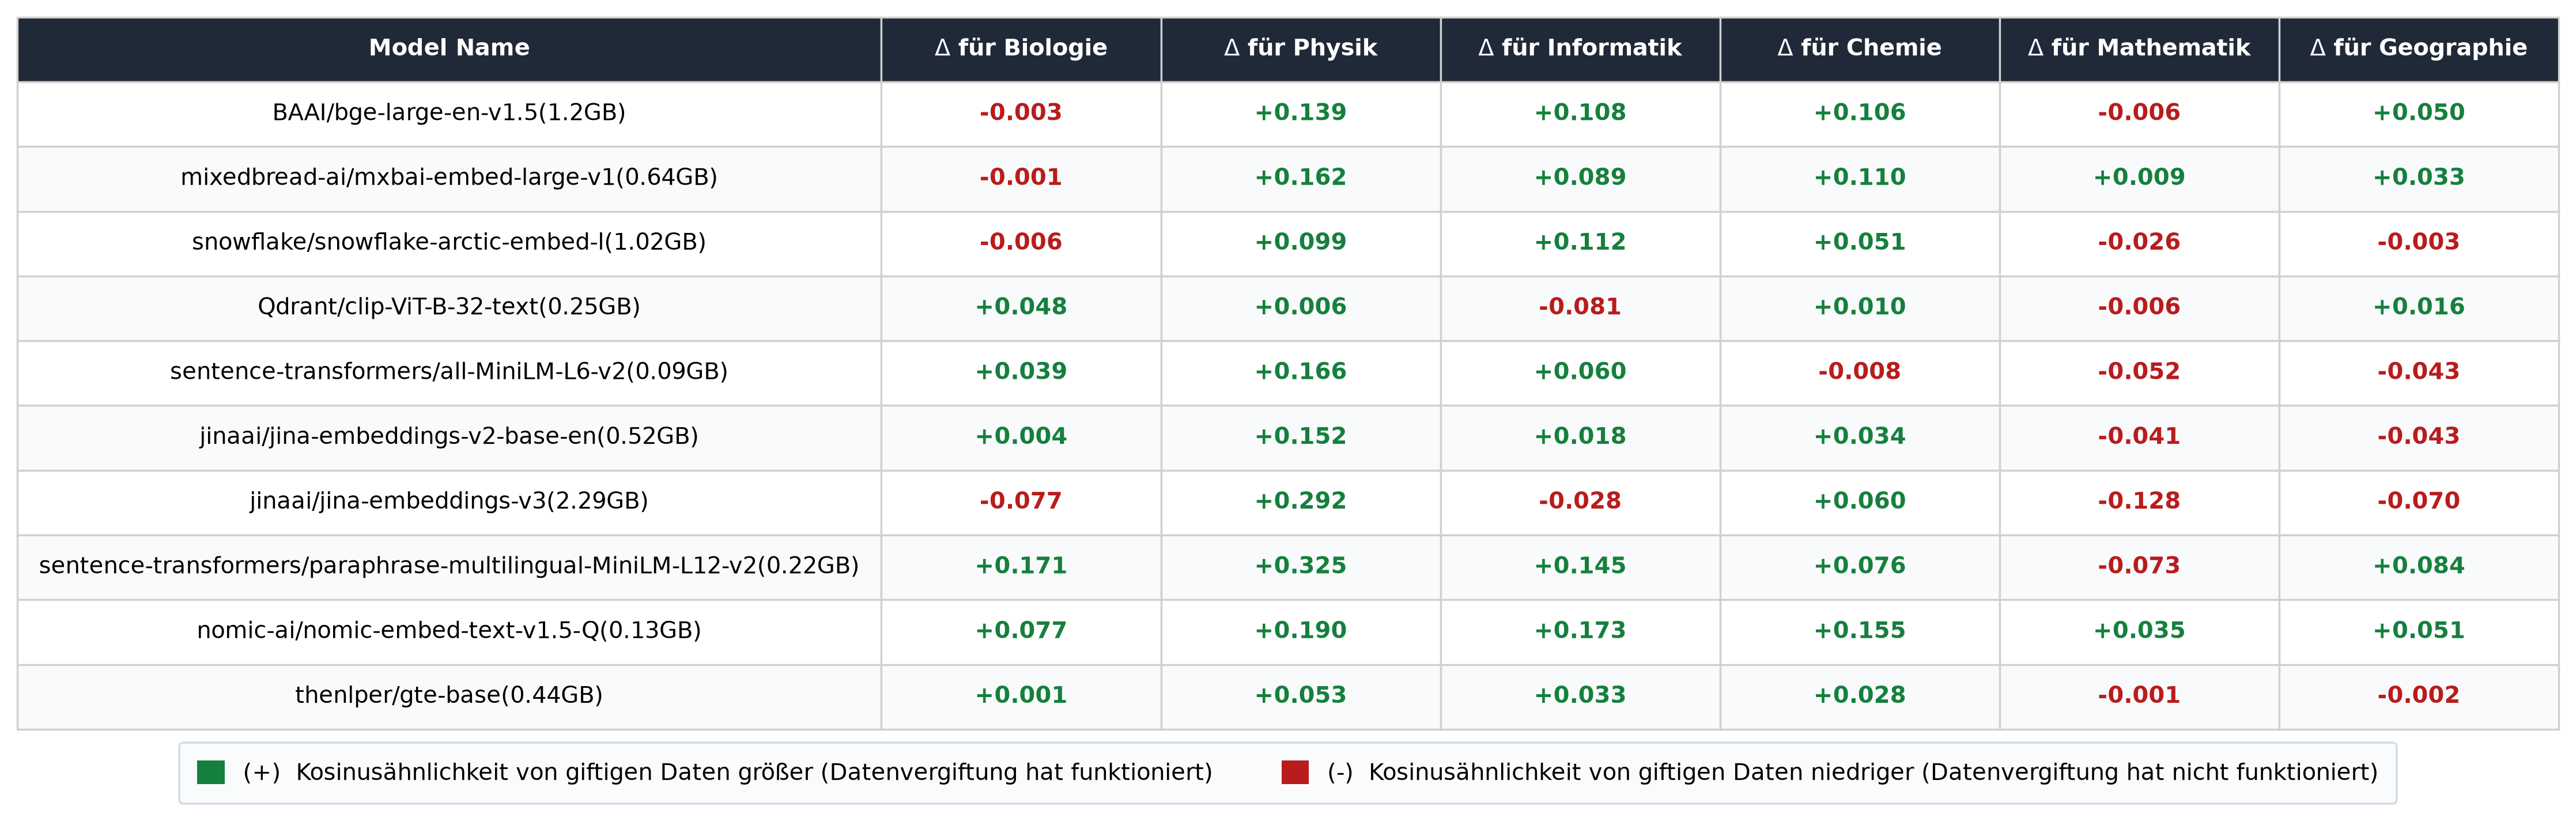

In [5]:
from matplotlib.patches import Patch

# Compute deltas and structure table contents
table_data = []
all_deltas = []  # 2D matrix matching [row_idx][col_idx] for styling

for row in raw_data:
    model_name = row[0]
    row_deltas = []
    row_strings = [model_name]

    for base, poison in row[1:]:
        delta = poison - base
        row_deltas.append(delta)
        delta_str = f"+{delta:.3f}" if delta > 0 else f"{delta:.3f}"
        row_strings.append(delta_str)

    table_data.append(row_strings)
    all_deltas.append(row_deltas)

# Create wide canvas figure
fig, ax = plt.subplots(figsize=(15, 4.4), dpi=300)
ax.axis("off")

# Generate Table
col_widths = [0.34] + [0.11] * 6

table = ax.table(
    cellText=table_data,
    colLabels=columns,
    colWidths=col_widths,
    loc="center",
    cellLoc="center",
)

table.auto_set_font_size(False)
table.set_fontsize(9.5)
table.scale(1.0, 1.9)

# Apply Cell Styling, Alignments, and Colors
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#d0d0d0")
    cell.set_linewidth(0.8)

    if row == 0:
        # Header formatting
        cell.set_facecolor("#1f2937")
        cell.get_text().set_color("white")
        cell.get_text().set_weight("bold")
    else:
        # Row backgrounds
        cell.set_facecolor("#f9fafb" if row % 2 == 0 else "#ffffff")

        # Column 0: Model name (left-aligned)
        if col == 0:
            cell._loc = "left"
        # Columns 1-6: Color-coded delta values
        elif col > 0:
            delta_val = all_deltas[row - 1][col - 1]
            cell.get_text().set_weight("bold")

            if delta_val >= 0:
                cell.get_text().set_color("#15803d")  # Green
            else:
                cell.get_text().set_color("#b91c1c")  # Red


legend_elements = [
    Patch(facecolor="#15803d", edgecolor="none", label="(+)  Kosinusähnlichkeit von giftigen Daten größer (Datenvergiftung hat funktioniert)"),
    Patch(facecolor="#b91c1c", edgecolor="none", label="(-)  Kosinusähnlichkeit von giftigen Daten niedriger (Datenvergiftung hat nicht funktioniert)")
]

legend = fig.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.03),  # (x=0.5 centers it, y=0.03 positions at bottom)
    ncol=2,                       # 2 columns side-by-side
    frameon=True,
    fontsize=9.5,
    handlelength=1.2,
    handleheight=1.2,
    borderpad=0.8,                # Controls inner box padding/height
    columnspacing=3.0             # Space between green and red items
)

legend.get_frame().set_facecolor("#f8fafc")
legend.get_frame().set_edgecolor("#cbd5e1")
legend.get_frame().set_linewidth(0.9)

plt.tight_layout()

#plt.savefig("delta_scores.svg", format="svg", bbox_inches="tight")
plt.show()